# 06B — EfficientNet Image-Only Classification

This notebook trains an image-only benign vs malignant classifier using EfficientNet-B0.

It is intended as a baseline comparison against the multimodal classifier:

- Image-only baseline: Ultrasound image → EfficientNet → classifier
- Multimodal model: Ultrasound image + clinical data → EfficientNet + ClinicalBERT → fusion → classifier

## 1. Imports and project setup

In [1]:
# from google.colab import drive
# drive.mount("/content/drive")

In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# PROJECT_ROOT = Path("/content/drive/MyDrive/breast-ultrasound-fyp")

PROJECT_ROOT = Path("..").resolve()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

IMAGE_DIR = RAW_DIR / "images"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("IMAGE_DIR exists:", IMAGE_DIR.exists())
print("PROCESSED_DIR exists:", PROCESSED_DIR.exists())

Device: cuda
GPU: NVIDIA GeForce GTX 1650
IMAGE_DIR exists: True
PROCESSED_DIR exists: True


## 2. Load the existing train / validation / test splits

Using the same splits as the multimodal model is important. It ensures that any difference in performance is due to the model inputs/architecture rather than a different data split.

In [3]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "val.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTraining class distribution:")
print(train_df["Classification"].value_counts())

Train: 176
Validation: 38
Test: 38

Training class distribution:
Classification
benign       108
malignant     68
Name: count, dtype: int64


## 3. Image-only dataset

Training-only augmentation is used to reduce overfitting:

- horizontal flip
- small rotation (±10°)
- mild brightness adjustment
- mild contrast adjustment

Validation and test images are not augmented.

The ImageNet mean and standard deviation are used because the EfficientNet backbone starts from ImageNet-pretrained weights.

In [4]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


class BreastImageClassificationDataset(Dataset):
    def __init__(
        self,
        dataframe,
        image_dir,
        image_size=224,
        augment=False
    ):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / row["Image_filename"]

        image = Image.open(image_path).convert("L")

        image = image.resize(
            (self.image_size, self.image_size),
            Image.BILINEAR
        )

        if self.augment:
            if random.random() < 0.5:
                image = TF.hflip(image)

            angle = random.uniform(-10, 10)
            image = TF.rotate(
                image,
                angle,
                interpolation=InterpolationMode.BILINEAR
            )

            brightness_factor = random.uniform(0.9, 1.1)
            image = TF.adjust_brightness(
                image,
                brightness_factor
            )

            contrast_factor = random.uniform(0.9, 1.1)
            image = TF.adjust_contrast(
                image,
                contrast_factor
            )

        image = np.array(
            image,
            dtype=np.float32
        ) / 255.0

        image = torch.tensor(
            image,
            dtype=torch.float32
        ).unsqueeze(0)

        image = image.repeat(3, 1, 1)

        image = (image - IMAGENET_MEAN) / IMAGENET_STD

        target = torch.tensor(
            row["target"],
            dtype=torch.float32
        )

        return image, target

## 4. Create datasets and DataLoaders

In [5]:
IMAGE_SIZE = 224
BATCH_SIZE = 8

train_dataset = BreastImageClassificationDataset(
    train_df,
    IMAGE_DIR,
    image_size=IMAGE_SIZE,
    augment=True
)

val_dataset = BreastImageClassificationDataset(
    val_df,
    IMAGE_DIR,
    image_size=IMAGE_SIZE,
    augment=False
)

test_dataset = BreastImageClassificationDataset(
    test_df,
    IMAGE_DIR,
    image_size=IMAGE_SIZE,
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, targets = next(iter(train_loader))

print("Images:", images.shape)
print("Targets:", targets.shape)
print("Targets:", targets)

Images: torch.Size([8, 3, 224, 224])
Targets: torch.Size([8])
Targets: tensor([0., 1., 0., 1., 1., 0., 0., 1.])


## 5. EfficientNet image-only classifier

EfficientNet-B0 is initialized with ImageNet-pretrained weights.

The original ImageNet classifier is replaced by a binary classification head


The output is a logit, so sigmoid is only applied when converting the output into a malignancy probability.

In [6]:
class EfficientNetImageClassifier(nn.Module):
    def __init__(self, dropout=0.4):
        super().__init__()

        self.model = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        in_features = self.model.classifier[1].in_features

        self.model.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(in_features, 1)
        )

    def forward(self, x):
        return self.model(x).squeeze(1)


model = EfficientNetImageClassifier(
    dropout=0.4
).to(device)

## 6. Freeze the EfficientNet feature extractor initially

training stage only trains the new classification head.

In [7]:
for parameter in model.model.features.parameters():
    parameter.requires_grad = False

for parameter in model.model.classifier.parameters():
    parameter.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)
print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

Trainable parameters: 1281
Total parameters: 4008829
Trainable percentage: 0.03%


## 7. Loss function

pos_weight gives the malignant class slightly more importance during training.

In [8]:
num_benign = (train_df["target"] == 0).sum()
num_malignant = (train_df["target"] == 1).sum()

pos_weight = torch.tensor(
    [num_benign / num_malignant],
    dtype=torch.float32,
    device=device
)

print("Benign:", num_benign)
print("Malignant:", num_malignant)
print("Positive class weight:", pos_weight.item())

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

Benign: 108
Malignant: 68
Positive class weight: 1.5882352590560913


## 8. Optimizer and scheduler

AdamW is used with weight decay for regularization. ReduceLROnPlateau lowers the learning rate if validation ROC-AUC stops improving.

In [9]:
optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-3
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

## 9. Validation helper

ROC-AUC is used for model selection because it evaluates how well the model separates benign and malignant cases across classification thresholds.

In [10]:
def evaluate_classifier(model, loader):
    model.eval()

    running_loss = 0.0

    all_targets = []
    all_probs = []
    all_preds = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(
                device,
                non_blocking=True
            )

            targets = targets.to(
                device,
                non_blocking=True
            )

            logits = model(images)

            loss = criterion(
                logits,
                targets
            )

            running_loss += loss.item()

            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()

            all_targets.extend(
                targets.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

    avg_loss = running_loss / len(loader)

    accuracy = accuracy_score(
        all_targets,
        all_preds
    )

    precision = precision_score(
        all_targets,
        all_preds,
        zero_division=0
    )

    recall = recall_score(
        all_targets,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_targets,
        all_preds,
        zero_division=0
    )

    auc = roc_auc_score(
        all_targets,
        all_probs
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": auc,
        "targets": all_targets,
        "probabilities": all_probs,
        "predictions": all_preds
    }

## 10. Stage 1 training — classifier head only

Early stopping is based on validation ROC-AUC. The best checkpoint is saved as:

`models/best_efficientnet_image_classifier.pth`

In [11]:
EPOCHS = 30
PATIENCE = 5

best_val_auc = -1.0
patience_counter = 0

train_losses = []
val_losses = []
val_aucs = []

for epoch in range(EPOCHS):
    model.train()

    # Keep the frozen EfficientNet backbone in eval mode so its
    # BatchNorm statistics do not drift on this small dataset.
    model.model.features.eval()

    running_train_loss = 0.0

    for images, targets in train_loader:
        images = images.to(
            device,
            non_blocking=True
        )

        targets = targets.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(
            logits,
            targets
        )

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    train_loss = (
        running_train_loss
        / len(train_loader)
    )

    val_metrics = evaluate_classifier(
        model,
        val_loader
    )

    val_loss = val_metrics["loss"]
    val_auc = val_metrics["auc"]

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_aucs.append(val_auc)

    scheduler.step(val_auc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_metrics['accuracy']:.4f} | "
        f"Recall: {val_metrics['recall']:.4f} | "
        f"F1: {val_metrics['f1']:.4f} | "
        f"AUC: {val_auc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        patience_counter = 0

        torch.save(
            model.state_dict(),
            MODEL_DIR /
            "best_efficientnet_image_classifier.pth"
        )

        print(
            f"Best model saved "
            f"(Val AUC={best_val_auc:.4f})"
        )

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping.")
            break

Epoch 01/30 | Train Loss: 0.8525 | Val Loss: 0.8387 | Accuracy: 0.6316 | Recall: 0.4667 | F1: 0.5000 | AUC: 0.6000 | LR: 1.00e-03
Best model saved (Val AUC=0.6000)
Epoch 02/30 | Train Loss: 0.8301 | Val Loss: 0.8049 | Accuracy: 0.6316 | Recall: 0.8667 | F1: 0.6500 | AUC: 0.6464 | LR: 1.00e-03
Best model saved (Val AUC=0.6464)
Epoch 03/30 | Train Loss: 0.7919 | Val Loss: 0.7826 | Accuracy: 0.6579 | Recall: 0.6000 | F1: 0.5806 | AUC: 0.6957 | LR: 1.00e-03
Best model saved (Val AUC=0.6957)
Epoch 04/30 | Train Loss: 0.7915 | Val Loss: 0.7858 | Accuracy: 0.6842 | Recall: 0.4667 | F1: 0.5385 | AUC: 0.7246 | LR: 1.00e-03
Best model saved (Val AUC=0.7246)
Epoch 05/30 | Train Loss: 0.7333 | Val Loss: 0.7547 | Accuracy: 0.7368 | Recall: 0.8000 | F1: 0.7059 | AUC: 0.7565 | LR: 1.00e-03
Best model saved (Val AUC=0.7565)
Epoch 06/30 | Train Loss: 0.7282 | Val Loss: 0.7320 | Accuracy: 0.7105 | Recall: 0.8000 | F1: 0.6857 | AUC: 0.7913 | LR: 1.00e-03
Best model saved (Val AUC=0.7913)
Epoch 07/30 | Tr

## 11. Plot training history

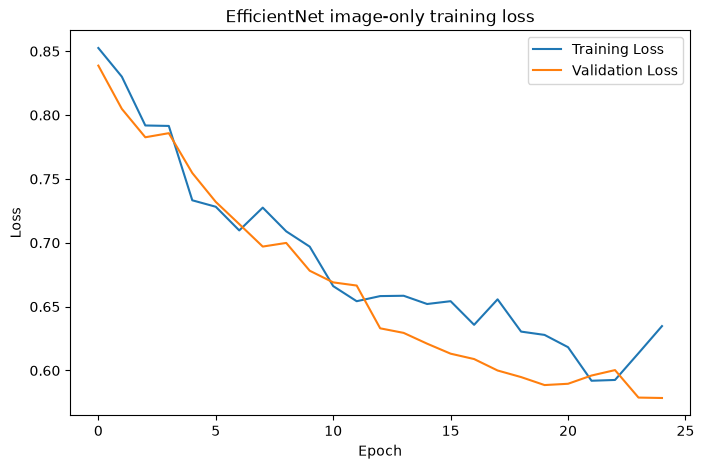

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet image-only training loss")
plt.legend()
plt.show()

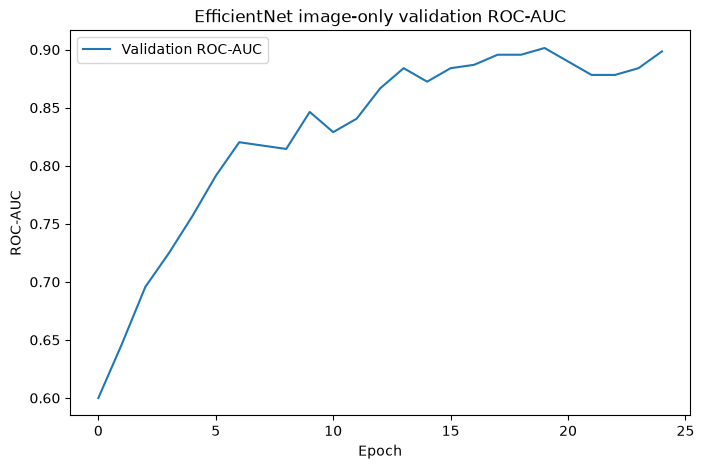

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    val_aucs,
    label="Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("EfficientNet image-only validation ROC-AUC")
plt.legend()
plt.show()

## 12. Stage 2 — fine-tune the final EfficientNet block

The classifier-head-only model is the safest baseline for a small dataset.


In [14]:
# Load the best stage-1 model first
model.load_state_dict(
    torch.load(
        MODEL_DIR /
        "best_efficientnet_image_classifier.pth",
        map_location=device
    )
)

# Freeze all feature blocks
for parameter in model.model.features.parameters():
    parameter.requires_grad = False

# Unfreeze only the final EfficientNet feature block
for parameter in model.model.features[-1].parameters():
    parameter.requires_grad = True

# Keep classifier trainable
for parameter in model.model.classifier.parameters():
    parameter.requires_grad = True

finetune_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-3
)

FINETUNE_EPOCHS = 10
FINETUNE_PATIENCE = 3

best_finetune_auc = best_val_auc
finetune_patience_counter = 0

for epoch in range(FINETUNE_EPOCHS):
    model.train()

    running_loss = 0.0

    for images, targets in train_loader:
        images = images.to(
            device,
            non_blocking=True
        )

        targets = targets.to(
            device,
            non_blocking=True
        )

        finetune_optimizer.zero_grad()

        logits = model(images)

        loss = criterion(
            logits,
            targets
        )

        loss.backward()
        finetune_optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    val_metrics = evaluate_classifier(
        model,
        val_loader
    )

    print(
        f"Fine-tune {epoch + 1:02d}/{FINETUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Accuracy: {val_metrics['accuracy']:.4f} | "
        f"Recall: {val_metrics['recall']:.4f} | "
        f"F1: {val_metrics['f1']:.4f} | "
        f"AUC: {val_metrics['auc']:.4f}"
    )

    if val_metrics["auc"] > best_finetune_auc:
        best_finetune_auc = val_metrics["auc"]
        finetune_patience_counter = 0

        torch.save(
            model.state_dict(),
            MODEL_DIR /
            "best_efficientnet_image_classifier.pth"
        )

        print(
            f"Improved fine-tuned model saved "
            f"(Val AUC={best_finetune_auc:.4f})"
        )

    else:
        finetune_patience_counter += 1

        if (
            finetune_patience_counter
            >= FINETUNE_PATIENCE
        ):
            print("Fine-tuning early stopping.")
            break

Fine-tune 01/10 | Train Loss: 0.8746 | Val Loss: 0.7017 | Accuracy: 0.8158 | Recall: 0.6667 | F1: 0.7407 | AUC: 0.8058
Fine-tune 02/10 | Train Loss: 0.7985 | Val Loss: 0.7538 | Accuracy: 0.7632 | Recall: 0.4667 | F1: 0.6087 | AUC: 0.7942
Fine-tune 03/10 | Train Loss: 0.8726 | Val Loss: 0.8526 | Accuracy: 0.6842 | Recall: 0.3333 | F1: 0.4545 | AUC: 0.6928
Fine-tuning early stopping.


## 13. Final held-out test evaluation

Once model selection is complete using the validation set, load the best checkpoint and evaluate it on the held-out test set.

In [ ]:
model.load_state_dict(
    torch.load(
        MODEL_DIR /
        "best_efficientnet_image_classifier.pth",
        map_location=device
    )
)

model.eval()

test_metrics = evaluate_classifier(
    model,
    test_loader
)

print(f"Accuracy:  {test_metrics['accuracy']:.4f}")

print(f"Precision: {test_metrics['precision']:.4f}")

print(f"Recall:    {test_metrics['recall']:.4f}")

print(f"F1-score:  {test_metrics['f1']:.4f}")

print(f"ROC-AUC:   {test_metrics['auc']:.4f}")

Accuracy:  0.7105
Precision: 0.6429
Recall:    0.6000
F1-score:  0.6207
ROC-AUC:   0.7971


In [16]:
print(
    classification_report(
        test_metrics["targets"],
        test_metrics["predictions"],
        target_names=[
            "Benign",
            "Malignant"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Benign       0.75      0.78      0.77        23
   Malignant       0.64      0.60      0.62        15

    accuracy                           0.71        38
   macro avg       0.70      0.69      0.69        38
weighted avg       0.71      0.71      0.71        38



## 14. Confusion matrix

[[18  5]
 [ 6  9]]


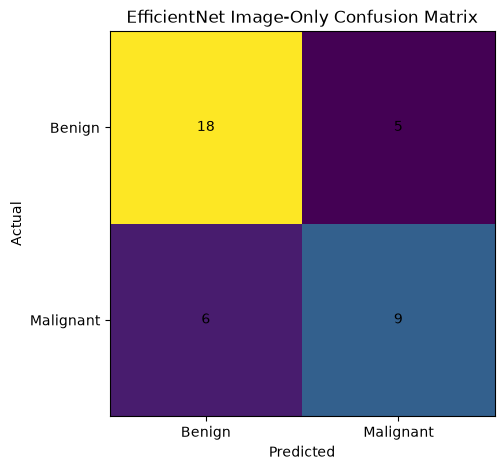

In [17]:
cm = confusion_matrix(
    test_metrics["targets"],
    test_metrics["predictions"]
)

print(cm)

plt.figure(figsize=(5, 5))
plt.imshow(cm)

plt.xticks(
    [0, 1],
    ["Benign", "Malignant"]
)

plt.yticks(
    [0, 1],
    ["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNet Image-Only Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

## 15. ROC curve

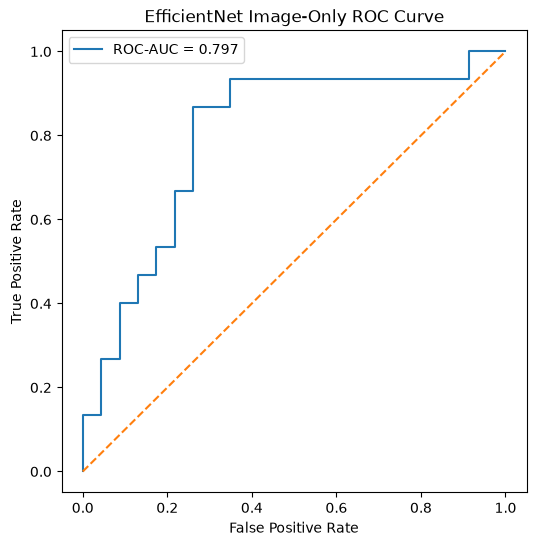

In [18]:
fpr, tpr, _ = roc_curve(
    test_metrics["targets"],
    test_metrics["probabilities"]
)

plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    label=(
        f"ROC-AUC = "
        f"{test_metrics['auc']:.3f}"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EfficientNet Image-Only ROC Curve")
plt.legend()
plt.show()

## 16. Save image-only results

In [19]:
image_only_results = pd.DataFrame({
    "CaseID": test_df["CaseID"].tolist(),
    "True_label": test_df[
        "Classification"
    ].tolist(),
    "True_target": test_metrics[
        "targets"
    ],
    "Predicted_target": test_metrics[
        "predictions"
    ],
    "Malignancy_probability": test_metrics[
        "probabilities"
    ]
})

image_only_results[
    "Predicted_label"
] = image_only_results[
    "Predicted_target"
].map({
    0.0: "benign",
    1.0: "malignant"
})

image_only_results.to_csv(
    OUTPUT_DIR /
    "efficientnet_image_only_results.csv",
    index=False
)

image_only_results.head()

,CaseID,True_label,True_target,Predicted_target,Malignancy_probability,Predicted_label
0,207,benign,0.0,1.0,0.576809,malignant
1,92,benign,0.0,0.0,0.166081,benign
2,153,malignant,1.0,0.0,0.466772,benign
3,201,benign,0.0,1.0,0.617771,malignant
4,73,benign,0.0,1.0,0.815082,malignant


## 17. Comparison with the multimodal classifier

multimodal test results are:

| Metric | Multimodal model |
|---|---:|
| Accuracy | 0.7895 |
| Precision | 0.8182 |
| Recall | 0.6000 |
| F1-score | 0.6923 |
| ROC-AUC | 0.7913 |
